Схема успешно сохранена в файл gost_flowchart_task1.png


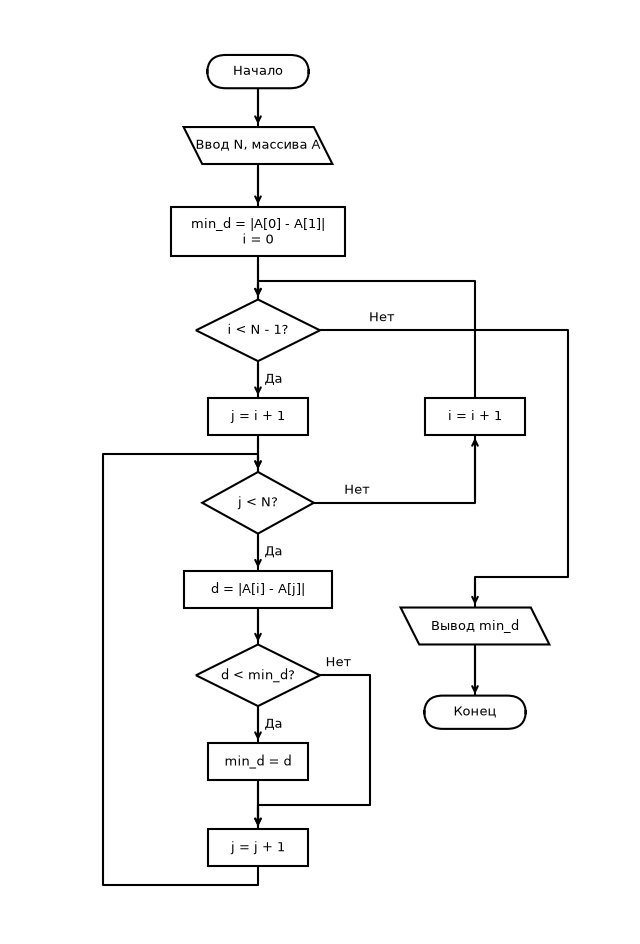

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def draw_flowchart():
    # Создаем холст нужного размера
    fig, ax = plt.subplots(figsize=(8, 12))
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 150)
    ax.axis('off')

    # Функции для отрисовки блоков по ГОСТ
    def box(x, y, w, h, text):
        ax.add_patch(patches.Rectangle((x - w/2, y - h/2), w, h, fill=True, color='white', ec='black', lw=1.5, zorder=2))
        ax.text(x, y, text, ha='center', va='center', fontsize=9, zorder=3)

    def diamond(x, y, w, h, text):
        ax.add_patch(patches.Polygon([(x, y+h/2), (x+w/2, y), (x, y-h/2), (x-w/2, y)], fill=True, color='white', ec='black', lw=1.5, zorder=2))
        ax.text(x, y, text, ha='center', va='center', fontsize=9, zorder=3)

    def io_block(x, y, w, h, text):
        ax.add_patch(patches.Polygon([(x-w/2+3, y-h/2), (x+w/2, y-h/2), (x+w/2-3, y+h/2), (x-w/2, y+h/2)], fill=True, color='white', ec='black', lw=1.5, zorder=2))
        ax.text(x, y, text, ha='center', va='center', fontsize=9, zorder=3)

    def oval(x, y, w, h, text):
        ax.add_patch(patches.FancyBboxPatch((x-w/2, y-h/2), w, h, boxstyle="round,pad=0.2,rounding_size=3", fill=True, color='white', ec='black', lw=1.5, zorder=2))
        ax.text(x, y, text, ha='center', va='center', fontsize=9, zorder=3)

    def arrow(pts, label='', lx=0, ly=0):
        x, y = zip(*pts)
        ax.plot(x, y, color='black', lw=1.5, zorder=1)
        ax.annotate("", xy=pts[-1], xytext=pts[-2], arrowprops=dict(arrowstyle="->", lw=1.5, color='black'), zorder=1)
        if label:
            ax.text(lx, ly, label, ha='center', va='center', fontsize=9, zorder=3, bbox=dict(facecolor='white', edgecolor='none', pad=1))

    # Отрисовка самих блоков строго по центру оси X = 40
    oval(40, 140, 16, 5, "Начало")
    io_block(40, 128, 24, 6, "Ввод N, массива A")
    box(40, 114, 28, 8, "min_d = |A[0] - A[1]|\ni = 0")
    diamond(40, 98, 20, 10, "i < N - 1?")
    box(40, 84, 16, 6, "j = i + 1")
    diamond(40, 70, 18, 10, "j < N?")
    box(40, 56, 24, 6, "d = |A[i] - A[j]|")
    diamond(40, 42, 20, 10, "d < min_d?")
    box(40, 28, 16, 6, "min_d = d")
    box(40, 14, 16, 6, "j = j + 1")
    
    # Блоки ветки "Нет" для вывода и завершения сдвинуты вправо на X = 75
    box(75, 84, 16, 6, "i = i + 1")
    io_block(75, 50, 24, 6, "Вывод min_d")
    oval(75, 36, 16, 5, "Конец")

    # Прямые стрелки основного потока (Да)
    arrow([(40, 137.5), (40, 131)])
    arrow([(40, 125), (40, 118)])
    arrow([(40, 110), (40, 103)])
    arrow([(40, 93), (40, 87)], "Да", 42.5, 90)
    arrow([(40, 81), (40, 75)])
    arrow([(40, 65), (40, 59)], "Да", 42.5, 62)
    arrow([(40, 53), (40, 47)])
    arrow([(40, 37), (40, 31)], "Да", 42.5, 34)
    arrow([(40, 25), (40, 17)])

    # Обходные стрелки (Нет) и правильные возвраты циклов под прямым углом
    # Ветка Нет от условия d < min_d к j = j + 1
    arrow([(50, 42), (58, 42), (58, 21), (40, 21), (40, 17)], "Нет", 53, 44) 
    
    # Возврат внутреннего цикла по переменной j
    arrow([(40, 11), (40, 8), (15, 8), (15, 78), (40, 78), (40, 75)]) 
    
    # Ветка Нет от условия j < N к i = i + 1
    arrow([(49, 70), (75, 70), (75, 81)], "Нет", 56, 72) 
    
    # Возврат внешнего цикла по переменной i
    arrow([(75, 87), (75, 106), (40, 106), (40, 103)]) 
    
    # Ветка Нет от условия i < N - 1 к блоку вывода
    arrow([(50, 98), (90, 98), (90, 58), (75, 58), (75, 53)], "Нет", 60, 100) 
    arrow([(75, 47), (75, 38.5)])

    # Сохранение результата
    plt.savefig("gost_flowchart_task1.png", dpi=300, bbox_inches='tight')
    print("Схема успешно сохранена в файл gost_flowchart_task1.png")

draw_flowchart()

Три схемы успешно сгенерированы!


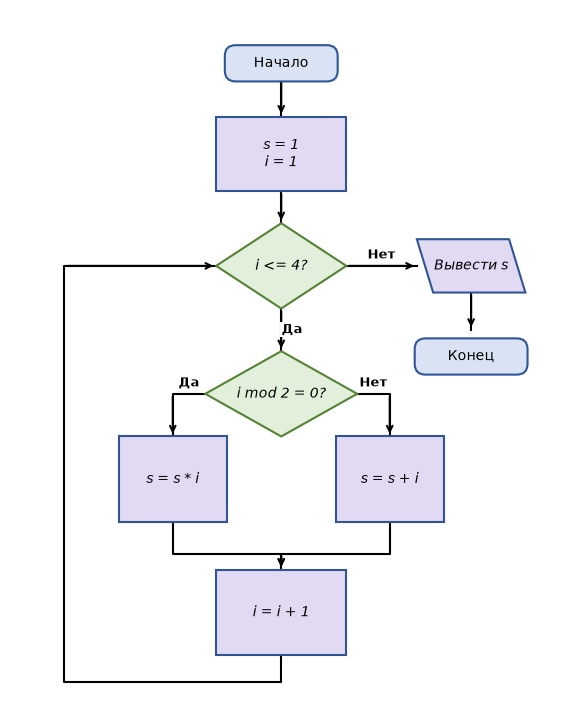

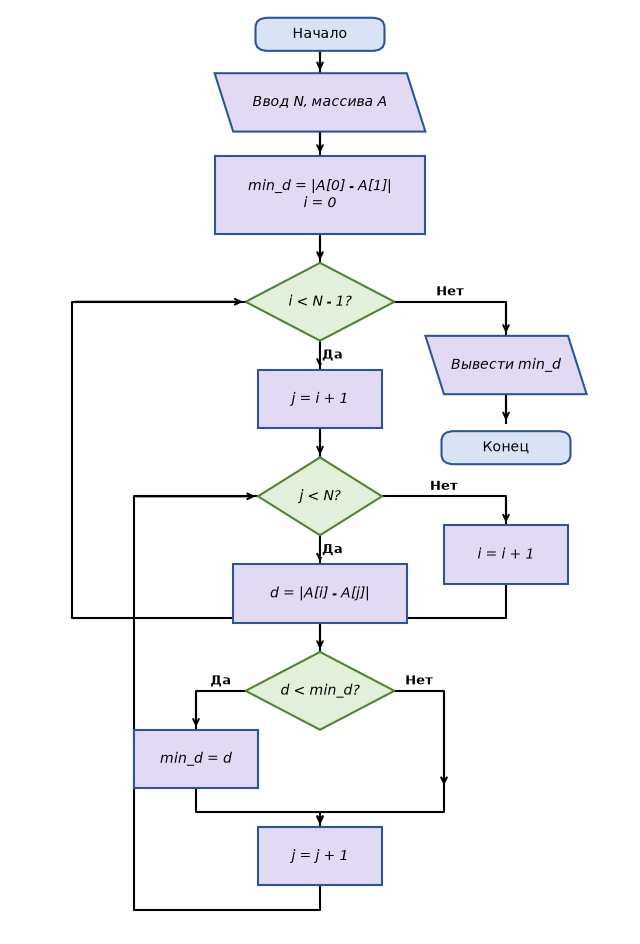

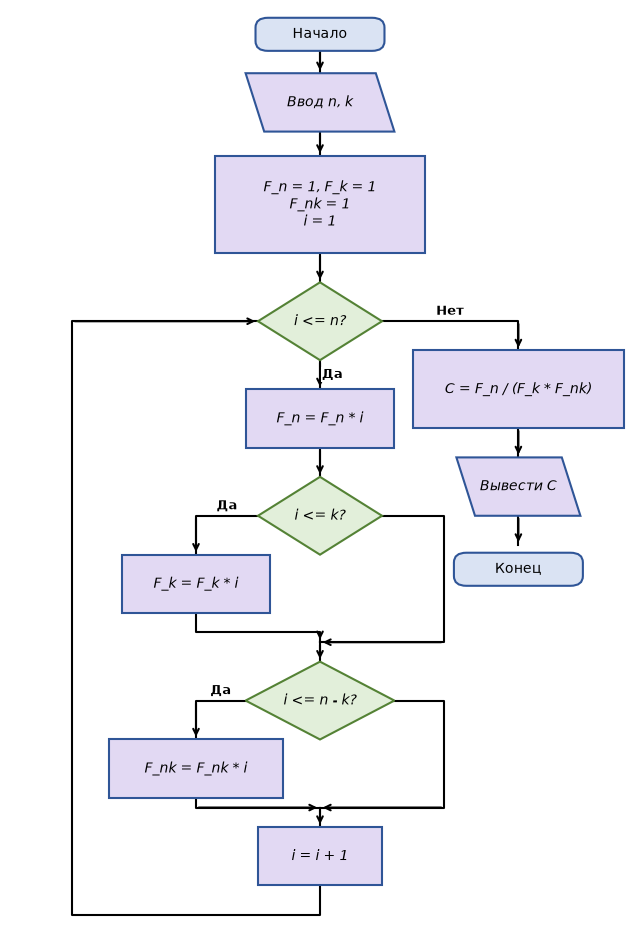

In [2]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def draw_all_flowcharts():
    # Вспомогательные функции для отрисовки красивых блоков в нужных цветах
    def add_oval(ax, x, y, w, h, text):
        ax.add_patch(patches.FancyBboxPatch((x-w/2, y-h/2), w, h, boxstyle="round,pad=0.4,rounding_size=2", facecolor='#dae3f3', edgecolor='#2f5597', lw=1.5, zorder=2))
        ax.text(x, y, text, ha='center', va='center', fontsize=10, zorder=3)

    def add_box(ax, x, y, w, h, text):
        ax.add_patch(patches.Rectangle((x - w/2, y - h/2), w, h, facecolor='#e2d9f3', edgecolor='#2f5597', lw=1.5, zorder=2))
        ax.text(x, y, text, ha='center', va='center', fontsize=10, style='italic', zorder=3)

    def add_diamond(ax, x, y, w, h, text):
        ax.add_patch(patches.Polygon([(x, y+h/2), (x+w/2, y), (x, y-h/2), (x-w/2, y)], facecolor='#e2efda', edgecolor='#548235', lw=1.5, zorder=2))
        ax.text(x, y, text, ha='center', va='center', fontsize=10, style='italic', zorder=3)

    def add_io(ax, x, y, w, h, text):
        ax.add_patch(patches.Polygon([(x-w/2+3, y-h/2), (x+w/2, y-h/2), (x+w/2-3, y+h/2), (x-w/2, y+h/2)], facecolor='#e2d9f3', edgecolor='#2f5597', lw=1.5, zorder=2))
        ax.text(x, y, text, ha='center', va='center', fontsize=10, style='italic', zorder=3)

    def add_arrow(ax, pts, label='', lx=0, ly=0):
        x_coords, y_coords = zip(*pts)
        ax.plot(x_coords, y_coords, color='black', lw=1.5, zorder=1)
        ax.annotate("", xy=pts[-1], xytext=pts[-2], arrowprops=dict(arrowstyle="->", lw=1.5, color='black'), zorder=1)
        if label:
            ax.text(lx, ly, label, ha='center', va='center', fontsize=9, fontweight='bold', zorder=3, bbox=dict(facecolor='white', edgecolor='none', pad=1))

    # --- СХЕМА 1: Домашнее задание (ДЗ 2) ---
    fig1, ax1 = plt.subplots(figsize=(7, 9))
    ax1.set_xlim(0, 100); ax1.set_ylim(-10, 120); ax1.axis('off')
    
    add_oval(ax1, 50, 110, 20, 6, "Начало")
    add_arrow(ax1, [(50, 107), (50, 100)])
    add_box(ax1, 50, 93, 24, 14, "s = 1\ni = 1")
    add_arrow(ax1, [(50, 86), (50, 80)])
    
    add_diamond(ax1, 50, 72, 24, 16, "i <= 4?")
    add_arrow(ax1, [(62, 72), (75, 72)], "Нет", 68.5, 74)
    add_io(ax1, 85, 72, 20, 10, "Вывести s")
    add_arrow(ax1, [(85, 67), (85, 60)])
    add_oval(ax1, 85, 55, 20, 6, "Конец")
    
    add_arrow(ax1, [(50, 64), (50, 56)], "Да", 52, 60)
    add_diamond(ax1, 50, 48, 28, 16, "i mod 2 = 0?")
    
    add_arrow(ax1, [(36, 48), (30, 48), (30, 40)], "Да", 33, 50)
    add_box(ax1, 30, 32, 20, 16, "s = s * i")
    
    add_arrow(ax1, [(64, 48), (70, 48), (70, 40)], "Нет", 67, 50)
    add_box(ax1, 70, 32, 20, 16, "s = s + i")
    
    add_arrow(ax1, [(30, 24), (30, 18), (50, 18), (50, 15)])
    add_arrow(ax1, [(70, 24), (70, 18), (50, 18), (50, 15)])
    add_box(ax1, 50, 7, 24, 16, "i = i + 1")
    
    # Возврат стрелки точно в левый угол ромба
    add_arrow(ax1, [(50, -1), (50, -6), (10, -6), (10, 72), (38, 72)])
    fig1.savefig("ДЗ_2_Блок_схема.png", dpi=300, bbox_inches='tight')

    # --- СХЕМА 2: Задача 1 (Минимальная разница) ---
    fig2, ax2 = plt.subplots(figsize=(8, 12))
    ax2.set_xlim(0, 100); ax2.set_ylim(-45, 145); ax2.axis('off')
    
    add_oval(ax2, 50, 140, 20, 6, "Начало")
    add_arrow(ax2, [(50, 137), (50, 132)])
    add_io(ax2, 50, 126, 34, 12, "Ввод N, массива A")
    add_arrow(ax2, [(50, 120), (50, 115)])
    add_box(ax2, 50, 107, 34, 16, "min_d = |A[0] - A[1]|\ni = 0")
    add_arrow(ax2, [(50, 99), (50, 93)])
    
    add_diamond(ax2, 50, 85, 24, 16, "i < N - 1?")
    add_arrow(ax2, [(62, 85), (80, 85), (80, 78)], "Нет", 71, 87)
    add_io(ax2, 80, 72, 26, 12, "Вывести min_d")
    add_arrow(ax2, [(80, 66), (80, 60)])
    add_oval(ax2, 80, 55, 20, 6, "Конец")
    
    add_arrow(ax2, [(50, 77), (50, 71)], "Да", 52, 74)
    add_box(ax2, 50, 65, 20, 12, "j = i + 1")
    add_arrow(ax2, [(50, 59), (50, 53)])
    
    add_diamond(ax2, 50, 45, 20, 16, "j < N?")
    add_arrow(ax2, [(60, 45), (80, 45), (80, 39)], "Нет", 70, 47)
    add_box(ax2, 80, 33, 20, 12, "i = i + 1")
    add_arrow(ax2, [(80, 27), (80, 20), (10, 20), (10, 85), (38, 85)])
    
    add_arrow(ax2, [(50, 37), (50, 31)], "Да", 52, 34)
    add_box(ax2, 50, 25, 28, 12, "d = |A[i] - A[j]|")
    add_arrow(ax2, [(50, 19), (50, 13)])
    
    add_diamond(ax2, 50, 5, 24, 16, "d < min_d?")
    add_arrow(ax2, [(38, 5), (30, 5), (30, -3)], "Да", 34, 7)
    add_box(ax2, 30, -9, 20, 12, "min_d = d")
    add_arrow(ax2, [(62, 5), (70, 5), (70, -15)], "Нет", 66, 7)
    
    add_arrow(ax2, [(30, -15), (30, -20), (50, -20), (50, -23)])
    add_arrow(ax2, [(70, -15), (70, -20), (50, -20), (50, -23)])
    add_box(ax2, 50, -29, 20, 12, "j = j + 1")
    add_arrow(ax2, [(50, -35), (50, -40), (20, -40), (20, 45), (40, 45)])
    fig2.savefig("Задача_1_Блок_схема.png", dpi=300, bbox_inches='tight')

    # --- СХЕМА 3: Задача 2 (Факториалы) ---
    fig3, ax3 = plt.subplots(figsize=(8, 12))
    ax3.set_xlim(0, 100); ax3.set_ylim(-45, 145); ax3.axis('off')
    
    add_oval(ax3, 50, 140, 20, 6, "Начало")
    add_arrow(ax3, [(50, 137), (50, 132)])
    add_io(ax3, 50, 126, 24, 12, "Ввод n, k")
    add_arrow(ax3, [(50, 120), (50, 115)])
    add_box(ax3, 50, 105, 34, 20, "F_n = 1, F_k = 1\nF_nk = 1\ni = 1")
    add_arrow(ax3, [(50, 95), (50, 89)])
    
    add_diamond(ax3, 50, 81, 20, 16, "i <= n?")
    add_arrow(ax3, [(60, 81), (82, 81), (82, 75)], "Нет", 71, 83)
    add_box(ax3, 82, 67, 34, 16, "C = F_n / (F_k * F_nk)")
    add_arrow(ax3, [(82, 59), (82, 53)])
    add_io(ax3, 82, 47, 20, 12, "Вывести C")
    add_arrow(ax3, [(82, 41), (82, 35)])
    add_oval(ax3, 82, 30, 20, 6, "Конец")
    
    add_arrow(ax3, [(50, 73), (50, 67)], "Да", 52, 70)
    add_box(ax3, 50, 61, 24, 12, "F_n = F_n * i")
    add_arrow(ax3, [(50, 55), (50, 49)])
    
    add_diamond(ax3, 50, 41, 20, 16, "i <= k?")
    add_arrow(ax3, [(40, 41), (30, 41), (30, 33)], "Да", 35, 43)
    add_box(ax3, 30, 27, 24, 12, "F_k = F_k * i")
    add_arrow(ax3, [(60, 41), (70, 41), (70, 15), (50, 15)])
    add_arrow(ax3, [(30, 21), (30, 17), (50, 17), (50, 15)])
    add_arrow(ax3, [(50, 15), (50, 11)])
    
    add_diamond(ax3, 50, 3, 24, 16, "i <= n - k?")
    add_arrow(ax3, [(38, 3), (30, 3), (30, -5)], "Да", 34, 5)
    add_box(ax3, 30, -11, 28, 12, "F_nk = F_nk * i")
    add_arrow(ax3, [(62, 3), (70, 3), (70, -19), (50, -19)])
    add_arrow(ax3, [(30, -17), (30, -19), (50, -19)])
    add_arrow(ax3, [(50, -19), (50, -23)])
    
    add_box(ax3, 50, -29, 20, 12, "i = i + 1")
    add_arrow(ax3, [(50, -35), (50, -41), (10, -41), (10, 81), (40, 81)])
    fig3.savefig("Задача_2_Блок_схема.png", dpi=300, bbox_inches='tight')
    
    print("Три схемы успешно сгенерированы!")

draw_all_flowcharts()

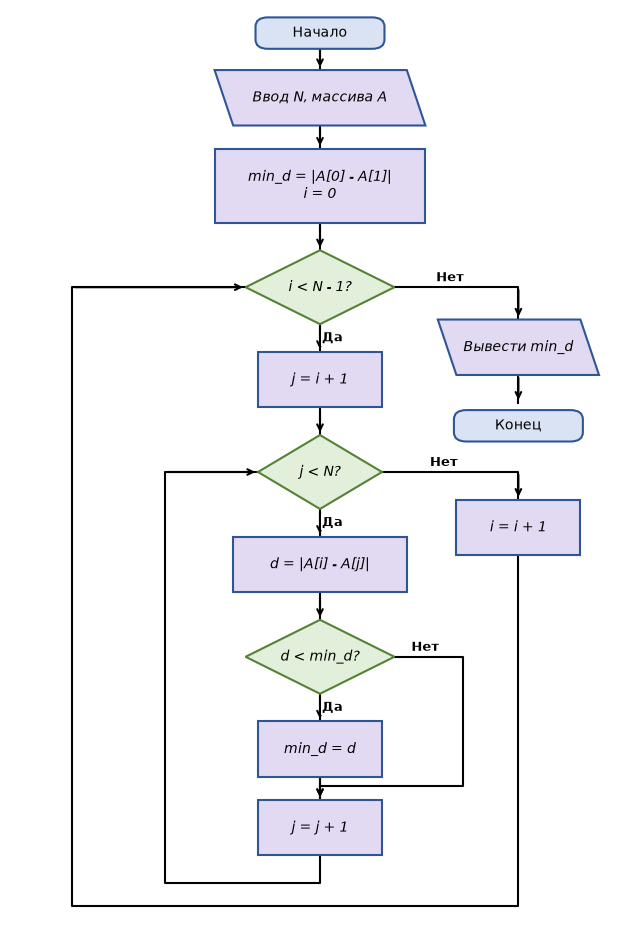

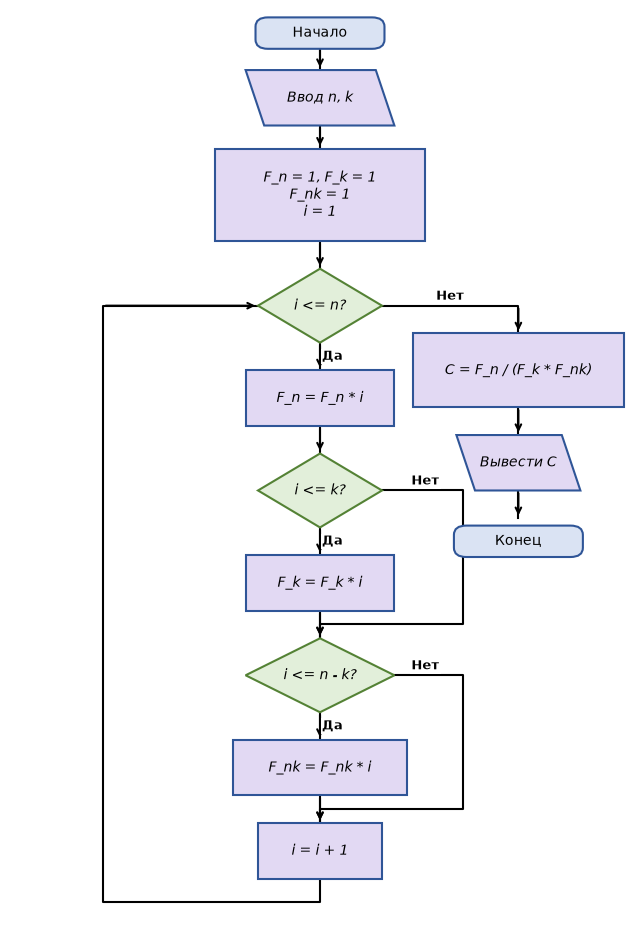

In [3]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def draw_perfect_flowcharts():
    def add_oval(ax, x, y, w, h, text):
        ax.add_patch(patches.FancyBboxPatch((x-w/2, y-h/2), w, h, boxstyle="round,pad=0.4,rounding_size=2", facecolor='#dae3f3', edgecolor='#2f5597', lw=1.5, zorder=2))
        ax.text(x, y, text, ha='center', va='center', fontsize=10, zorder=3)

    def add_box(ax, x, y, w, h, text):
        ax.add_patch(patches.Rectangle((x - w/2, y - h/2), w, h, facecolor='#e2d9f3', edgecolor='#2f5597', lw=1.5, zorder=2))
        ax.text(x, y, text, ha='center', va='center', fontsize=10, style='italic', zorder=3)

    def add_diamond(ax, x, y, w, h, text):
        ax.add_patch(patches.Polygon([(x, y+h/2), (x+w/2, y), (x, y-h/2), (x-w/2, y)], facecolor='#e2efda', edgecolor='#548235', lw=1.5, zorder=2))
        ax.text(x, y, text, ha='center', va='center', fontsize=10, style='italic', zorder=3)

    def add_io(ax, x, y, w, h, text):
        ax.add_patch(patches.Polygon([(x-w/2+3, y-h/2), (x+w/2, y-h/2), (x+w/2-3, y+h/2), (x-w/2, y+h/2)], facecolor='#e2d9f3', edgecolor='#2f5597', lw=1.5, zorder=2))
        ax.text(x, y, text, ha='center', va='center', fontsize=10, style='italic', zorder=3)

    def add_arrow(ax, pts, label='', lx=0, ly=0):
        x_coords, y_coords = zip(*pts)
        ax.plot(x_coords, y_coords, color='black', lw=1.5, zorder=1)
        ax.annotate("", xy=pts[-1], xytext=pts[-2], arrowprops=dict(arrowstyle="->", lw=1.5, color='black'), zorder=1)
        if label:
            ax.text(lx, ly, label, ha='center', va='center', fontsize=9, fontweight='bold', zorder=3, bbox=dict(facecolor='white', edgecolor='none', pad=1))

    # --- СХЕМА 1: Задача 1 (Минимальная разница) ---
    fig1, ax1 = plt.subplots(figsize=(8, 12))
    ax1.set_xlim(0, 100); ax1.set_ylim(-55, 145); ax1.axis('off')
    
    add_oval(ax1, 50, 140, 20, 6, "Начало")
    add_arrow(ax1, [(50, 137), (50, 132)])
    add_io(ax1, 50, 126, 34, 12, "Ввод N, массива A")
    add_arrow(ax1, [(50, 120), (50, 115)])
    add_box(ax1, 50, 107, 34, 16, "min_d = |A[0] - A[1]|\ni = 0")
    add_arrow(ax1, [(50, 99), (50, 93)])
    
    # Внешний цикл
    add_diamond(ax1, 50, 85, 24, 16, "i < N - 1?")
    add_arrow(ax1, [(62, 85), (82, 85), (82, 78)], "Нет", 71, 87)
    add_io(ax1, 82, 72, 26, 12, "Вывести min_d")
    add_arrow(ax1, [(82, 66), (82, 60)])
    add_oval(ax1, 82, 55, 20, 6, "Конец")
    
    add_arrow(ax1, [(50, 77), (50, 71)], "Да", 52, 74)
    add_box(ax1, 50, 65, 20, 12, "j = i + 1")
    add_arrow(ax1, [(50, 59), (50, 53)])
    
    # Внутренний цикл
    add_diamond(ax1, 50, 45, 20, 16, "j < N?")
    # Если внутренний цикл закончен, переходим к i = i + 1
    add_arrow(ax1, [(60, 45), (82, 45), (82, 39)], "Нет", 70, 47)
    add_box(ax1, 82, 33, 20, 12, "i = i + 1")
    # Возврат внешнего цикла (самая широкая дуга)
    add_arrow(ax1, [(82, 27), (82, -49), (10, -49), (10, 85), (38, 85)])
    
    add_arrow(ax1, [(50, 37), (50, 31)], "Да", 52, 34)
    add_box(ax1, 50, 25, 28, 12, "d = |A[i] - A[j]|")
    add_arrow(ax1, [(50, 19), (50, 13)])
    
    # Прямая ось для условия
    add_diamond(ax1, 50, 5, 24, 16, "d < min_d?")
    add_arrow(ax1, [(50, -3), (50, -9)], "Да", 52, -6)
    add_box(ax1, 50, -15, 20, 12, "min_d = d")
    add_arrow(ax1, [(50, -21), (50, -26)])
    
    # Ветка Нет обходит блок обновления справа
    add_arrow(ax1, [(62, 5), (73, 5), (73, -23), (50, -23), (50, -26)], "Нет", 67, 7)
    
    add_box(ax1, 50, -32, 20, 12, "j = j + 1")
    # Возврат внутреннего цикла (внутренняя дуга)
    add_arrow(ax1, [(50, -38), (50, -44), (25, -44), (25, 45), (40, 45)])
    
    fig1.savefig("Идеальная_Задача_1.png", dpi=300, bbox_inches='tight')

    # --- СХЕМА 2: Задача 2 (Факториалы) ---
    fig2, ax2 = plt.subplots(figsize=(8, 12))
    ax2.set_xlim(0, 100); ax2.set_ylim(-55, 145); ax2.axis('off')
    
    add_oval(ax2, 50, 140, 20, 6, "Начало")
    add_arrow(ax2, [(50, 137), (50, 132)])
    add_io(ax2, 50, 126, 24, 12, "Ввод n, k")
    add_arrow(ax2, [(50, 120), (50, 115)])
    add_box(ax2, 50, 105, 34, 20, "F_n = 1, F_k = 1\nF_nk = 1\ni = 1")
    add_arrow(ax2, [(50, 95), (50, 89)])
    
    add_diamond(ax2, 50, 81, 20, 16, "i <= n?")
    add_arrow(ax2, [(60, 81), (82, 81), (82, 75)], "Нет", 71, 83)
    add_box(ax2, 82, 67, 34, 16, "C = F_n / (F_k * F_nk)")
    add_arrow(ax2, [(82, 59), (82, 53)])
    add_io(ax2, 82, 47, 20, 12, "Вывести C")
    add_arrow(ax2, [(82, 41), (82, 35)])
    add_oval(ax2, 82, 30, 20, 6, "Конец")
    
    # Главная центральная ось алгоритма
    add_arrow(ax2, [(50, 73), (50, 67)], "Да", 52, 70)
    add_box(ax2, 50, 61, 24, 12, "F_n = F_n * i")
    add_arrow(ax2, [(50, 55), (50, 49)])
    
    add_diamond(ax2, 50, 41, 20, 16, "i <= k?")
    add_arrow(ax2, [(50, 33), (50, 27)], "Да", 52, 30)
    add_box(ax2, 50, 21, 24, 12, "F_k = F_k * i")
    add_arrow(ax2, [(50, 15), (50, 9)])
    # Пропуск умножения справа
    add_arrow(ax2, [(60, 41), (73, 41), (73, 12), (50, 12), (50, 9)], "Нет", 67, 43)
    
    add_diamond(ax2, 50, 1, 24, 16, "i <= n - k?")
    add_arrow(ax2, [(50, -7), (50, -13)], "Да", 52, -10)
    add_box(ax2, 50, -19, 28, 12, "F_nk = F_nk * i")
    add_arrow(ax2, [(50, -25), (50, -31)])
    # Пропуск умножения справа
    add_arrow(ax2, [(62, 1), (73, 1), (73, -28), (50, -28), (50, -31)], "Нет", 67, 3)
    
    add_box(ax2, 50, -37, 20, 12, "i = i + 1")
    # Красивый ровный возврат слева
    add_arrow(ax2, [(50, -43), (50, -48), (15, -48), (15, 81), (40, 81)])
    
    fig2.savefig("Идеальная_Задача_2.png", dpi=300, bbox_inches='tight')

draw_perfect_flowcharts()